In [1]:
import numpy as np
from matplotlib import pyplot as plt

In [2]:
def asarray_1d_float(x):
    part_1 = "x could not be converted to a "
    part_2 = "0D or 1D "
    part_3 = "numpy array of floats"
    try:
        X = np.asarray(x, dtype=float)
    except (TypeError, ValueError) as e:
        error_message = part_1 + part_3
        raise ValueError(error_message)
    if (X.ndim != 0) and (X.ndim != 1):    
        error_message = part_1 + part_2 + part_3
        raise ValueError(error_message)
    return X

In [3]:
def di2xy_without_proj(dec, inc):
    # Convert input to 1D numpy arrays of floats
    D = asarray_1d_float(dec)
    I = asarray_1d_float(inc)
    # Convert degrees to radians
    D = np.deg2rad(D)
    I = np.deg2rad(I)
    # Compute the Cartesian coordinates
    x = np.cos(I) * np.cos(D)
    y = np.cos(I) * np.sin(D)
    return x, y

In [4]:
def di2xy_equal_area(dec, inc):
    # Convert input to 1D numpy arrays of floats
    D = asarray_1d_float(dec)
    I = asarray_1d_float(inc)
    # Convert degrees to radians
    D = np.deg2rad(D)
    I = np.deg2rad(I)
    # Compute the Cartesian coordinates
    # r = np.sqrt(2 * (1 - np.sin(np.abs(I))))
    r = np.sqrt(1 - np.sin(np.abs(I)))
    x = r * np.cos(I) * np.cos(D)
    y = r * np.cos(I) * np.sin(D)
    # h = np.sqrt(x**2 + y**2)
    return x, y

In [5]:
dec = np.linspace(-180., 180., 30)
inc = np.broadcast_to(-50., (dec.size,))

In [6]:
x1, y1 = di2xy_without_proj(dec, inc)

In [7]:
x2, y2 = di2xy_equal_area(dec, inc)

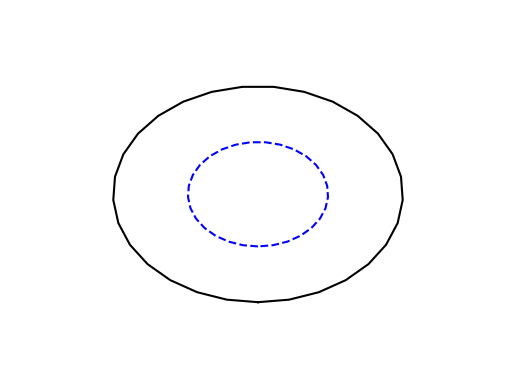

In [8]:
fig, ax = plt.subplots()

ax.plot(y1, x1, 'k-', label='without projection')
ax.plot(y2, x2, 'b--', label='equal area')

ax.axis("off")

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)

plt.show()

In [34]:
def plot_net(ax, projection=None):
    # # Verify the input
    # if isinstance(num_dec, int):
    #     raise ValueError("num_dec is not an integer")
    # if num_dec <= 0:
    #     raise ValueError("num_dec is not a positive integer")
    # if isinstance(num_inc, int):
    #     raise ValueError("num_inc is not an integer")
    # if num_inc <= 0:
    #     raise ValueError("num_inc is not a positive integer")
    
    if projection not in ['none', 'eqarea']:
        raise ValueError("invalid projection")
    
    func = {
        'none': di2xy_without_proj,
        'eqarea': di2xy_equal_area
    }
    
    # Declination and inclination values
    decs = np.arange(0, 361)
    incs = np.arange(0, 91)
    
    # Constant declination lines
    for inc in range(0, 80, 10):
        x, y = func[projection](
            decs, np.broadcast_to(inc, (decs.size,))
        )
        ax.plot(y, x, linestyle='-', linewidth=0.3, color=3*(0.3,))
    # Constant inclination lines
    for dec in range(0, 361-10, 10):
        x, y = func[projection](
            np.broadcast_to(dec, (incs.size,)), incs
        )
        ax.plot(y, x, linestyle='-', linewidth=0.3, color=3*(0.3,))

In [47]:
dec, inc = 45, 0

In [48]:
x1, y1 = di2xy_without_proj(dec, inc)

In [49]:
x2, y2 = di2xy_equal_area(dec, inc)

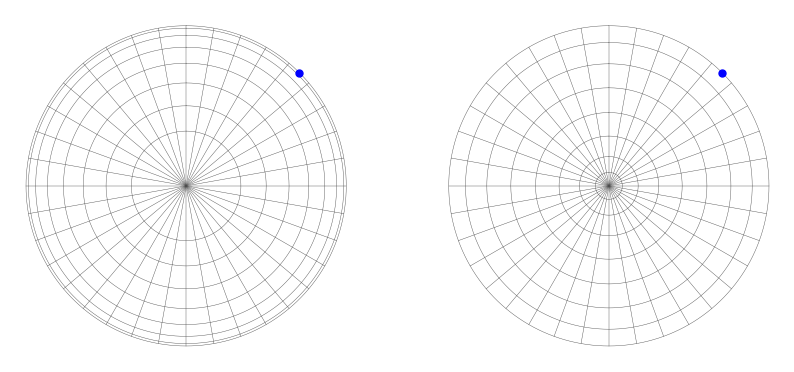

In [50]:
fig, (ax1, ax2) = plt.subplots(
    ncols=2, nrows=1, figsize=(10,10)
)

ax1.axis('scaled')
plot_net(ax1, 'none')
ax1.plot(y1, x1, 'bo', ms=5)
ax1.axis("off")
ax1.set_xlim(-1.1, 1.1)
ax1.set_ylim(-1.1, 1.1)

ax2.axis('scaled')
plot_net(ax2, 'eqarea')
ax2.plot(y2, x2, 'bo', ms=5)
ax2.axis("off")
ax2.set_xlim(-1.1, 1.1)
ax2.set_ylim(-1.1, 1.1)

plt.show()